# SVD Image Compression from Scratch

Image shape: (736, 736)


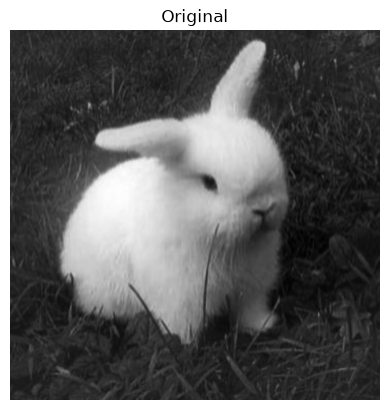

In [1]:
import numpy as np
import matplotlib.pyplot as plt

img = plt.imread(r'D:\deskstop\New folder\WhatsApp Image 2026-10-03 at 4.34.03 PM.jpeg')

if img.ndim == 3:
    gray = img[:, :, :3].mean(axis=2)
else:
    gray = img

gray = gray.astype(float)

print("Image shape:", gray.shape)

plt.imshow(gray, cmap='gray')
plt.title("Original")
plt.axis('off')
plt.show()

My top 5:    [62187.03 16677.79  8805.93  7150.3   6249.57]
NumPy top 5: [62187.03 16677.79  8805.93  7150.3   6249.57]


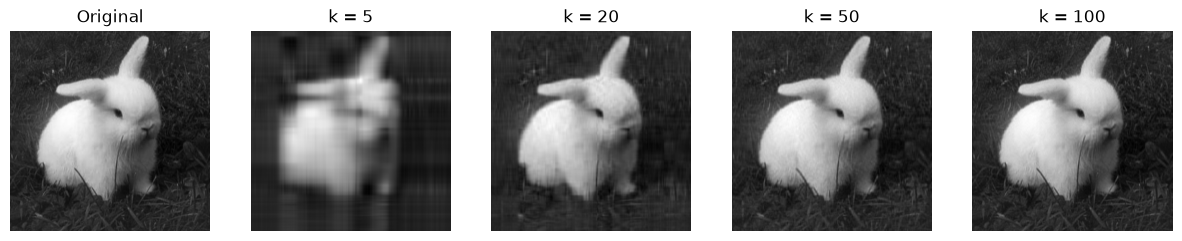

In [2]:
def power_iteration(A, num_iters=300, tol=1e-9):
    rng = np.random.default_rng(0)
    v = rng.standard_normal(A.shape[1])
    v /= np.linalg.norm(v)

    for _ in range(num_iters):
        u = A @ v
        u /= np.linalg.norm(u)
        v_new = A.T @ u
        v_new /= np.linalg.norm(v_new)
        if np.linalg.norm(v_new - v) < tol:
            v = v_new
            break
        v = v_new

    Av = A @ v
    sigma = np.linalg.norm(Av)   # importance of this layer
    u = Av / sigma
    return u, sigma, v


def my_svd(A, k):
    residual = A.copy()
    U_list, S_list, V_list = [], [], []
    for _ in range(k):
        u, s, v = power_iteration(residual)
        U_list.append(u); S_list.append(s); V_list.append(v)
        residual = residual - s * np.outer(u, v)   # remove this layer
    return np.array(U_list).T, np.array(S_list), np.array(V_list).T

k_max = 100
U, S, V = my_svd(gray, k_max)

# Check against numpy's SVD (baseline)
S_np = np.linalg.svd(gray, compute_uv=False)
print("My top 5:   ", S[:5].round(2))
print("NumPy top 5:", S_np[:5].round(2))

def reconstruct(k):
    return U[:, :k] @ np.diag(S[:k]) @ V[:, :k].T

ks = [5, 20, 50, 100]
plt.figure(figsize=(15, 4))
plt.subplot(1, 5, 1)
plt.imshow(gray, cmap='gray'); plt.title("Original"); plt.axis('off')
for i, k in enumerate(ks):
    plt.subplot(1, 5, i + 2)
    plt.imshow(reconstruct(k), cmap='gray')
    plt.title(f"k = {k}"); plt.axis('off')
plt.show()

   k        MSE  PSNR (dB)  Compression
   1    1006.24      18.10       367.8x
   2     492.76      21.20       183.9x
   5     183.12      25.50        73.6x
  10      74.34      29.42        36.8x
  20      35.61      32.62        18.4x
  30      22.48      34.61        12.3x
  50      10.35      37.98         7.4x
  75       4.19      41.91         4.9x
 100       1.70      45.83         3.7x


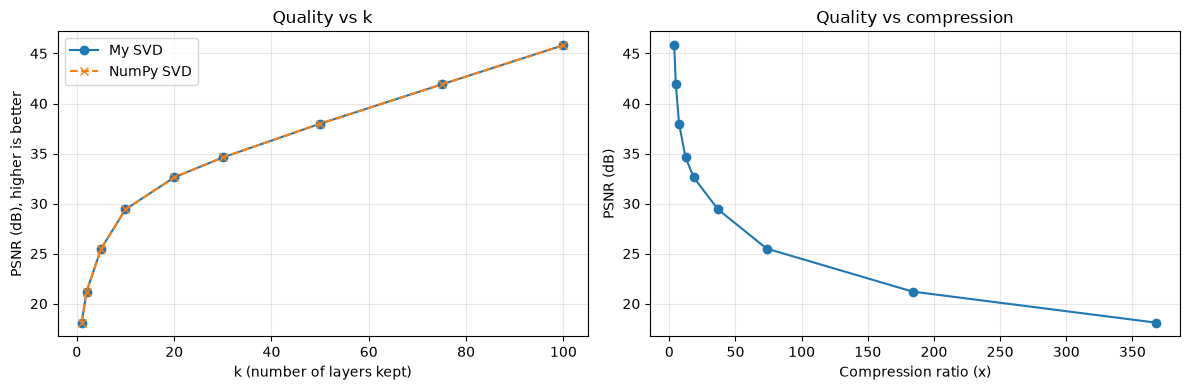

In [3]:
# Step 3: error and compression vs k
m, n = gray.shape
max_val = 255.0 if gray.max() > 1 else 1.0   # pixel range

def mse(a, b):
    return np.mean((a - b) ** 2)

def psnr(a, b):
    return 10 * np.log10(max_val**2 / mse(a, b))

# NumPy's SVD, used only as a baseline to compare against
U_np, S_np, Vt_np = np.linalg.svd(gray, full_matrices=False)
def reconstruct_np(k):
    return U_np[:, :k] @ np.diag(S_np[:k]) @ Vt_np[:k, :]

ks_all = [1, 2, 5, 10, 20, 30, 50, 75, 100]
my_psnr, np_psnr, ratios = [], [], []

print(f"{'k':>4} {'MSE':>10} {'PSNR (dB)':>10} {'Compression':>12}")
for k in ks_all:
    rec = reconstruct(k)
    my_psnr.append(psnr(gray, rec))
    np_psnr.append(psnr(gray, reconstruct_np(k)))
    # numbers stored: k*(m + n + 1) instead of m*n
    ratio = (m * n) / (k * (m + n + 1))
    ratios.append(ratio)
    print(f"{k:>4} {mse(gray, rec):>10.2f} {my_psnr[-1]:>10.2f} {ratio:>11.1f}x")

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(ks_all, my_psnr, 'o-', label='My SVD')
plt.plot(ks_all, np_psnr, 'x--', label='NumPy SVD')
plt.xlabel('k (number of layers kept)')
plt.ylabel('PSNR (dB), higher is better')
plt.title('Quality vs k')
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(ratios, my_psnr, 'o-')
plt.xlabel('Compression ratio (x)')
plt.ylabel('PSNR (dB)')
plt.title('Quality vs compression')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('svd_results.png', dpi=150)
plt.show()